# Kaplan–Meier Survival Curve

**Family:** Healthcare & life sciences &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Healthcare & life sciences:* Clinical trials, survival, oncology, hospital quality and operations, epidemiology and patient-level records.

> ⚠️ Examples use simulated data. De-identify patient data before analysing it in notebooks: executed notebooks store their outputs.

## Design purpose

A step function estimating the probability of remaining event-free over time while correctly handling censored subjects, meaning those whose follow-up ended before an event. It is the standard figure for time-to-event outcomes in clinical trials and cohort studies.

## When to use

- Compare overall survival, progression-free survival or time-to-relapse between treatment arms or risk groups
- Show any time-to-event outcome with censoring (churn, machine failure, time to readmission)
- Report median survival and survival at landmark times (1-year, 5-year)

## Avoid when

- Survival curves cross substantially (the log-rank test is weak; report RMST or landmark analyses as well)
- There are competing risks (use cumulative incidence functions)
- There are many groups (more than 3–4 curves become unreadable; facet instead)

## Alternatives

- Cumulative incidence plot
- Swimmer plot (patient-level detail)
- Forest plot of hazard ratios

## Design tips

- Always show a numbers-at-risk table aligned under the x-axis
- Mark censored observations with small ticks
- Show confidence bands and truncate the x-axis where few subjects remain at risk

## Example

A simulated two-arm oncology trial (120 patients per arm): true median overall survival is 12 months on control and 18 months on the new treatment (the estimated medians in the legend differ by chance), with administrative censoring at up to 48 months.

### Setup

In [1]:
import sys
from pathlib import Path
# This example uses the reusable vizlib package from this repository
# (or `pip install -e .` at the repo root).
sys.path.insert(0, str(Path(".").resolve().parents[1]))
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from scipy.stats import chi2
from vizlib.health import kaplan_meier as km_table

### Data

In [2]:
rng = np.random.default_rng(42)
def simulate(n, median):
    event_time = rng.exponential(median / np.log(2), n)
    censor_time = np.minimum(rng.uniform(12, 48, n), rng.exponential(80, n))
    t = np.minimum(event_time, censor_time).round(1)
    return t, (event_time <= censor_time).astype(int)
arms = {"Control": simulate(120, 12), "New treatment": simulate(120, 18)}
df = pd.concat([pd.DataFrame({"arm": a, "months": t, "event": e}) for a, (t, e) in arms.items()])

def kaplan_meier(t, e):
    """Kaplan-Meier estimate with 95% CI (Greenwood variance, log(-log) scale) from the tested
    vizlib.health module. Returns step times, S(t) and the CI, carried to the last follow-up."""
    km = km_table(t, e)
    end = max(t.max(), km["time"].max())
    pad = lambda col: np.r_[km[col].to_numpy(), km[col].iloc[-1]]
    return np.r_[km["time"].to_numpy(), end], pad("survival"), pad("ci_lower"), pad("ci_upper")


def logrank_p(t1, e1, t2, e2):
    O = E = V = 0.0
    for u in np.unique(np.r_[t1[e1 == 1], t2[e2 == 1]]):
        n1, n2 = (t1 >= u).sum(), (t2 >= u).sum()
        d1, d = ((t1 == u) & (e1 == 1)).sum(), ((t1 == u) & (e1 == 1)).sum() + ((t2 == u) & (e2 == 1)).sum()
        n = n1 + n2
        O += d1; E += d * n1 / n
        if n > 1:
            V += d * (n1 / n) * (n2 / n) * (n - d) / (n - 1)
    return chi2.sf((O - E) ** 2 / V, 1)

p_value = logrank_p(*arms["Control"], *arms["New treatment"])
ticks = np.arange(0, 49, 6)
title, xlabel, ylabel = ("Overall survival by treatment arm", "Months since randomisation",
                         "Overall survival probability")
df.groupby("arm").agg(patients=("event", "size"), events=("event", "sum"))

,patients,events
arm,,
Control,120,85
New treatment,120,60


### Plot

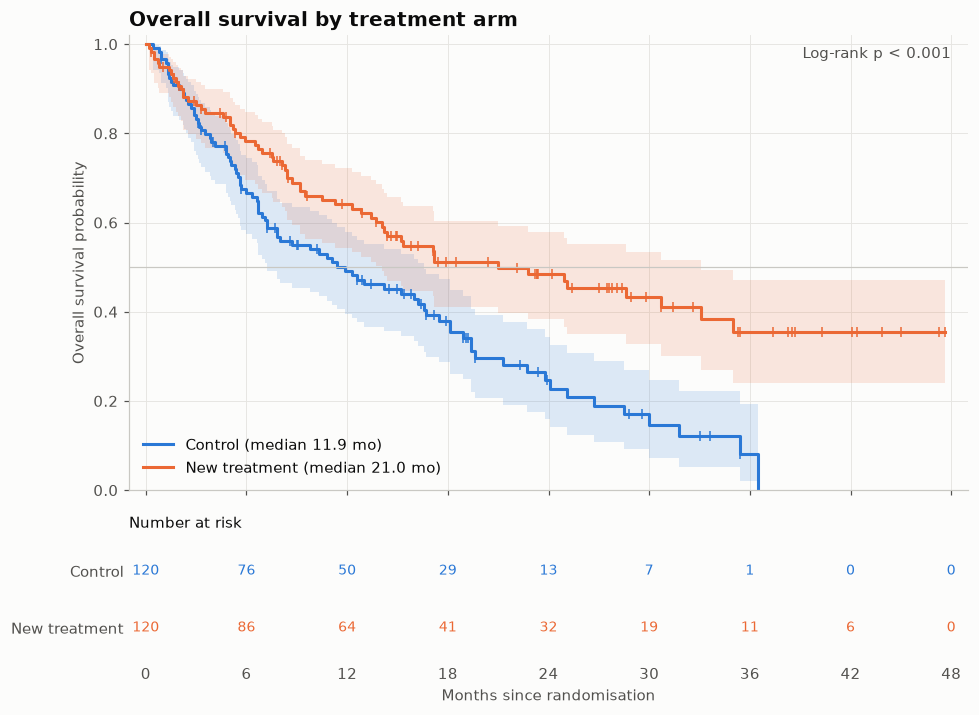

In [3]:
fig, (ax, axr) = plt.subplots(2, 1, figsize=(9, 6.6), height_ratios=[4, 1.1], sharex=True)
for i, (arm, (t, e)) in enumerate(arms.items()):
    x, s, lo, hi = kaplan_meier(t, e)
    med = x[np.argmax(s <= 0.5)] if (s <= 0.5).any() else np.nan
    ax.step(x, s, where="post", color=PALETTE[i], label=f"{arm} (median {med:.1f} mo)")
    ax.fill_between(x, lo, hi, step="post", color=PALETTE[i], alpha=0.15, linewidth=0)
    ct = t[e == 0]
    ax.plot(ct, s[np.searchsorted(x, ct, side="right") - 1], "|", color=PALETTE[i], markersize=7)
    for tk in ticks:
        axr.text(tk, 1 - i, str((t >= tk).sum()), ha="center", va="center", color=PALETTE[i], fontsize=9)
ax.axhline(0.5, color="#c9c8c3", linewidth=0.8)
ax.set_ylim(0, 1.02); ax.set_ylabel(ylabel)
ax.set_title(title)
ax.text(0.98, 0.95, "Log-rank p < 0.001" if p_value < 0.001 else f"Log-rank p = {p_value:.3f}", transform=ax.transAxes, ha="right", color="#52514e")
ax.legend(loc="lower left")
axr.set_ylim(-0.6, 1.6); axr.set_yticks([1, 0], list(arms)); axr.grid(False)
axr.set_xticks(ticks); axr.set_xlim(-ticks[-1] / 48, ticks[-1] + 1); axr.set_xlabel(xlabel)
axr.set_title("Number at risk", fontsize=10, fontweight="normal")
for side in ("left", "bottom"):
    axr.spines[side].set_visible(False)
axr.tick_params(length=0)
fig.tight_layout()
plt.show()

## How to read it

Each step down is one or more deaths, and the ticks are censored patients. A curve that stays higher means better survival. Read the median where each curve crosses 0.5, and check the at-risk table: estimates far to the right rest on few patients.

## Try it with real data

**Source:** lifelines.datasets.load_waltons (fruit-fly lifespans by group, bundled offline)

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [4]:
from lifelines.datasets import load_waltons

waltons = load_waltons()
arms = {g: (d["T"].to_numpy(float), d["E"].to_numpy(int))
        for g, d in waltons.groupby("group", sort=True)}            # "control", "miR-137"
arms = {"Control": arms["control"], "miR-137 knockdown": arms["miR-137"]}
p_value = logrank_p(*arms["Control"], *arms["miR-137 knockdown"])
ticks = np.arange(0, 76, 12)
title, xlabel, ylabel = ("Fruit-fly lifespan: control vs. miR-137 knockdown (Waltons data)",
                         "Days", "Probability still alive")
waltons.groupby("group").agg(flies=("E", "size"), deaths=("E", "sum"))

,flies,deaths
group,,
control,129,122
miR-137,34,34


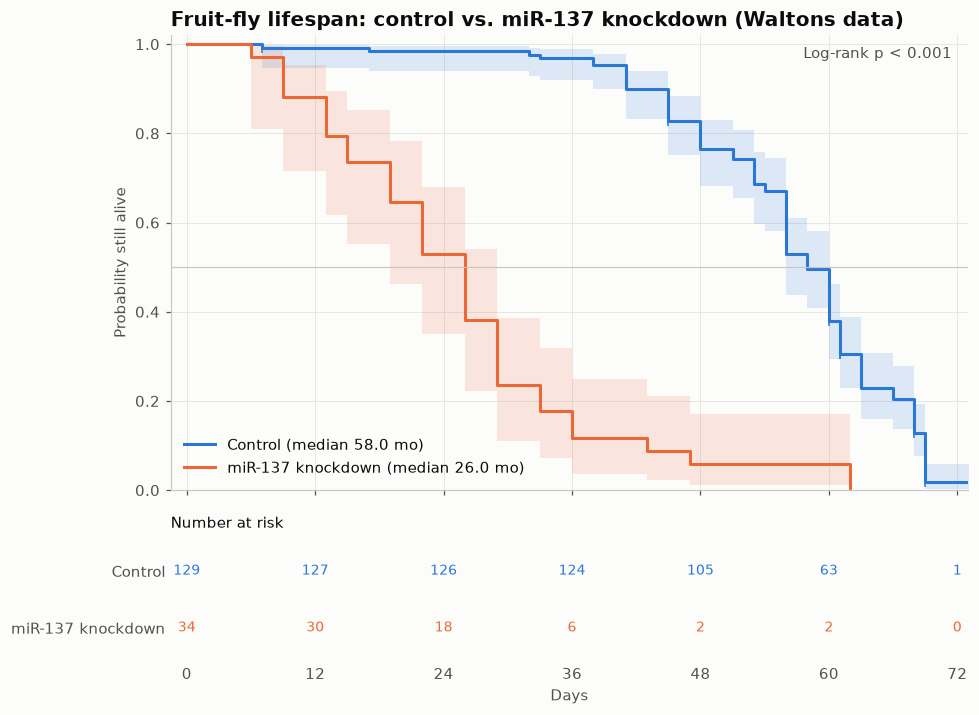

In [5]:
fig, (ax, axr) = plt.subplots(2, 1, figsize=(9, 6.6), height_ratios=[4, 1.1], sharex=True)
for i, (arm, (t, e)) in enumerate(arms.items()):
    x, s, lo, hi = kaplan_meier(t, e)
    med = x[np.argmax(s <= 0.5)] if (s <= 0.5).any() else np.nan
    ax.step(x, s, where="post", color=PALETTE[i], label=f"{arm} (median {med:.1f} mo)")
    ax.fill_between(x, lo, hi, step="post", color=PALETTE[i], alpha=0.15, linewidth=0)
    ct = t[e == 0]
    ax.plot(ct, s[np.searchsorted(x, ct, side="right") - 1], "|", color=PALETTE[i], markersize=7)
    for tk in ticks:
        axr.text(tk, 1 - i, str((t >= tk).sum()), ha="center", va="center", color=PALETTE[i], fontsize=9)
ax.axhline(0.5, color="#c9c8c3", linewidth=0.8)
ax.set_ylim(0, 1.02); ax.set_ylabel(ylabel)
ax.set_title(title)
ax.text(0.98, 0.95, "Log-rank p < 0.001" if p_value < 0.001 else f"Log-rank p = {p_value:.3f}", transform=ax.transAxes, ha="right", color="#52514e")
ax.legend(loc="lower left")
axr.set_ylim(-0.6, 1.6); axr.set_yticks([1, 0], list(arms)); axr.grid(False)
axr.set_xticks(ticks); axr.set_xlim(-ticks[-1] / 48, ticks[-1] + 1); axr.set_xlabel(xlabel)
axr.set_title("Number at risk", fontsize=10, fontweight="normal")
for side in ("left", "bottom"):
    axr.spines[side].set_visible(False)
axr.tick_params(length=0)
fig.tight_layout()
plt.show()

---
Standalone script: [`kaplan_meier.py`](kaplan_meier.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)